# Course 11: On-Device AI
## Session 6: Knowledge distillation

**Goal:** train a small student MLP from a large teacher's softened outputs, compare it with the same student trained directly with all labels and with few labels, sweep the temperature and the loss weight, see what the T² factor does, and quantize the distilled student.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. Setup, teacher and student
**Knowledge distillation** (Hinton, Vinyals & Dean 2015) trains a small **student** to imitate a large **teacher**. Our teacher is an MLP with two hidden layers of 512 units and dropout (301,066 parameters); our student has one hidden layer of 16 units (1,210 parameters, 249 times fewer). Data: the 8 × 8 digits, 1,257 training and 540 test images.

Every run uses the same step-based trainer: Adam, 64 examples per batch, a fixed number of steps. The loss mixes the ordinary cross-entropy with the true labels and a **soft** term that matches the teacher's softened output distribution:

$$L = \alpha \, \text{CE}(y, z_s) + (1 - \alpha)\, T^2\, \text{KL}\big(\text{softmax}(z_t / T)\,\|\,\text{softmax}(z_s / T)\big),$$

where $z_t, z_s$ are the teacher's and student's logits and $T$ is the **temperature**. $\alpha = 1$ is ordinary training. Small networks vary from seed to seed, so every student result is the mean over **three seeds**, with the spread.

In [1]:
import os
for _v in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ[_v] = "1"                     # one BLAS thread for NumPy; set before NumPy is imported
import time, copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

torch.set_num_threads(1)
torch.manual_seed(0); np.random.seed(0)
t_start = time.time()

digits = load_digits()
X = torch.tensor(digits.data / 16.0, dtype=torch.float32); y = torch.tensor(digits.target)
perm = np.random.default_rng(0).permutation(len(y))
tr, te = perm[:1257], perm[1257:]
Xtr, ytr, Xte, yte = X[tr], y[tr], X[te], y[te]

def mlp(hidden, seed, dropout=0.0):
    torch.manual_seed(seed)
    layers, prev = [], 64
    for h in hidden:
        layers += [nn.Linear(prev, h), nn.ReLU()] + ([nn.Dropout(dropout)] if dropout else [])
        prev = h
    return nn.Sequential(*layers, nn.Linear(prev, 10))

def train_student(model, steps, X_l=None, y_l=None, X_s=None, soft=None, T=4.0, alpha=1.0, t2=True, seed=0, lr=3e-3):
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    model.train()
    for _ in range(steps):
        loss = 0.0
        if alpha > 0:                                                   # hard labels
            b = torch.randint(0, len(X_l), (min(64, len(X_l)),), generator=g)
            loss = loss + alpha * F.cross_entropy(model(X_l[b]), y_l[b])
        if alpha < 1:                                                   # teacher's soft targets on the transfer set
            b = torch.randint(0, len(X_s), (64,), generator=g)
            kl = F.kl_div(F.log_softmax(model(X_s[b]) / T, dim=1), F.softmax(soft[b] / T, dim=1), reduction="batchmean")
            loss = loss + (1 - alpha) * (T * T if t2 else 1.0) * kl
        opt.zero_grad(); loss.backward(); opt.step()
    return model.eval()

def accuracy(model):
    with torch.no_grad():
        return (model(Xte).argmax(1) == yte).float().mean().item()

def three_seeds(make_run):
    a = np.array([make_run(s) for s in range(3)])
    return a.mean(), a.min(), a.max()

teacher = train_student(mlp([512, 512], 0, dropout=0.2), 800, Xtr, ytr, lr=1e-3)
with torch.no_grad():
    t_logits = teacher(Xtr)                                             # computed once, reused by every student
n_t = sum(p.numel() for p in teacher.parameters()); n_s = sum(p.numel() for p in mlp([16], 0).parameters())
print(f"teacher: {n_t:,d} parameters ({4 * n_t / 1e3:.0f} kB in float32), test accuracy {accuracy(teacher):.3f}")
print(f"student: {n_s:,d} parameters ({4 * n_s / 1e3:.1f} kB in float32)")

teacher: 301,066 parameters (1204 kB in float32), test accuracy 0.985
student: 1,210 parameters (4.8 kB in float32)


### 2. With all 1,257 labels: does distillation help?
The fair baseline is the **same student trained directly** on the same labels, for the same number of steps (1,200 here, about 60 epochs), not the teacher. We compare it with distillation at $T = 4$ and two loss weights.

In [2]:
full = {}
full["student, labels only"] = three_seeds(lambda s: accuracy(train_student(mlp([16], s), 1200, Xtr, ytr, seed=s)))
for alpha in [0.5, 0.1]:
    full[f"distilled, T = 4, alpha = {alpha}"] = three_seeds(lambda s: accuracy(train_student(
        mlp([16], s), 1200, Xtr, ytr, Xtr, t_logits, T=4.0, alpha=alpha, seed=s)))
for k, (m, lo, hi) in full.items():
    print(f"{k:32s}: mean {m:.3f} (seeds {lo:.3f} to {hi:.3f})")
print(f"teacher: {accuracy(teacher):.3f}")

student, labels only            : mean 0.972 (seeds 0.969 to 0.976)
distilled, T = 4, alpha = 0.5   : mean 0.976 (seeds 0.972 to 0.980)
distilled, T = 4, alpha = 0.1   : mean 0.972 (seeds 0.969 to 0.974)
teacher: 0.985


### 3. With 50 labels: what kind of data does the student learn from?
Now suppose only **50 labelled images** (5 per class) are available, but a strong teacher exists (here: the teacher above, trained on all labels, standing in for a large model trained elsewhere on much more data). Distillation needs inputs, not labels, so the **transfer set** can be:

* the 50 labelled images only;
* **augmented** copies of them: each image shifted by one pixel up, down, left and right (250 inputs);
* **unlabelled** images: the other 1,207 training images, with their labels thrown away.

Every run takes 800 steps.

In [3]:
rng = np.random.default_rng(0)
lab = np.concatenate([rng.choice(np.where(ytr.numpy() == c)[0], 5, replace=False) for c in range(10)])
unl = np.setdiff1d(np.arange(len(ytr)), lab)
X50, y50 = Xtr[lab], ytr[lab]

def shifted(x):                                       # one-pixel shifts of 8 x 8 images, filled with zeros
    im, out = x.reshape(-1, 8, 8), []
    for dy, dx in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
        s = torch.roll(im, shifts=(dy, dx), dims=(1, 2))
        if dy == 1: s[:, 0, :] = 0
        if dy == -1: s[:, -1, :] = 0
        if dx == 1: s[:, :, 0] = 0
        if dx == -1: s[:, :, -1] = 0
        out.append(s)
    return torch.cat(out).reshape(-1, 64)

X_aug = torch.cat([X50, shifted(X50)])
X_unl = Xtr[unl]
with torch.no_grad():
    soft50, soft_aug, soft_unl = teacher(X50), teacher(X_aug), teacher(X_unl)
low = {}
low["student, 50 labels only"] = three_seeds(lambda s: accuracy(train_student(mlp([16], s), 800, X50, y50, seed=s)))
for name, Xs, soft in [("distilled, transfer = the 50 images", X50, soft50),
                       ("distilled, transfer = 50 + shifted copies", X_aug, soft_aug),
                       ("distilled, transfer = 1,207 unlabelled", X_unl, soft_unl)]:
    low[name] = three_seeds(lambda s: accuracy(train_student(mlp([16], s), 800, X50, y50, Xs, soft, T=4.0, alpha=0.5, seed=s)))
for k, (m, lo, hi) in low.items():
    print(f"{k:42s}: mean {m:.3f} (seeds {lo:.3f} to {hi:.3f})")

student, 50 labels only                   : mean 0.840 (seeds 0.830 to 0.848)
distilled, transfer = the 50 images       : mean 0.892 (seeds 0.887 to 0.896)
distilled, transfer = 50 + shifted copies : mean 0.948 (seeds 0.946 to 0.950)
distilled, transfer = 1,207 unlabelled    : mean 0.962 (seeds 0.957 to 0.967)


### 4. Temperature and loss weight
With $T = 1$ the teacher's output is close to one-hot: it says *which* digit, little more. A higher $T$ softens it and reveals what Hinton et al. call **dark knowledge**: which wrong answers the teacher finds plausible (a 7 that looks a little like a 1). We sweep $T \in \{1, 2, 4, 8\}$ at $\alpha = 0.5$ and $\alpha \in \{0, 0.25, 0.5, 0.75, 0.9\}$ at $T = 4$, in the 50-label setting with the unlabelled transfer set, where distillation matters. The first line shows how soft the teacher's targets are at each temperature.

T = 1: teacher's top probability on average 0.998, entropy 0.012 nats (max 2.303)
T = 2: teacher's top probability on average 0.972, entropy 0.131 nats (max 2.303)
T = 4: teacher's top probability on average 0.808, entropy 0.766 nats (max 2.303)
T = 8: teacher's top probability on average 0.468, entropy 1.747 nats (max 2.303)


temperature sweep (alpha = 0.5): T=1: 0.965, T=2: 0.965, T=4: 0.962, T=8: 0.957
alpha sweep (T = 4):            alpha=0.0: 0.957, alpha=0.25: 0.960, alpha=0.5: 0.962, alpha=0.75: 0.962, alpha=0.9: 0.952


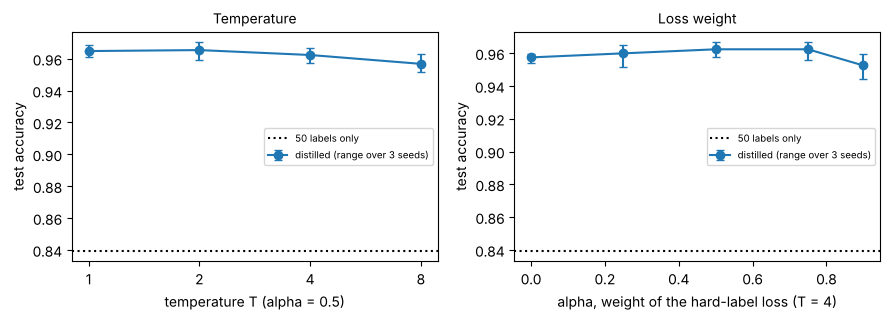

In [4]:
with torch.no_grad():
    for T in [1, 2, 4, 8]:
        p = F.softmax(soft_unl / T, dim=1)
        ent = -(p * p.clamp_min(1e-12).log()).sum(1).mean().item()
        print(f"T = {T}: teacher's top probability on average {p.max(1).values.mean().item():.3f}, entropy {ent:.3f} nats (max {np.log(10):.3f})")
sweep_T = {T: three_seeds(lambda s: accuracy(train_student(mlp([16], s), 800, X50, y50, X_unl, soft_unl, T=T, alpha=0.5, seed=s)))
           for T in [1, 2, 4, 8]}
sweep_a = {a: three_seeds(lambda s: accuracy(train_student(mlp([16], s), 800, X50, y50, X_unl, soft_unl, T=4.0, alpha=a, seed=s)))
           for a in [0.0, 0.25, 0.5, 0.75, 0.9]}
print("temperature sweep (alpha = 0.5): " + ", ".join(f"T={T}: {m:.3f}" for T, (m, _, _) in sweep_T.items()))
print("alpha sweep (T = 4):            " + ", ".join(f"alpha={a}: {m:.3f}" for a, (m, _, _) in sweep_a.items()))

fig, ax = plt.subplots(1, 2, figsize=(9, 3.3))
for axis, sw, xlabel in [(ax[0], sweep_T, "temperature T (alpha = 0.5)"), (ax[1], sweep_a, "alpha, weight of the hard-label loss (T = 4)")]:
    xs = list(sw); m = [sw[k][0] for k in xs]
    err = [[sw[k][0] - sw[k][1] for k in xs], [sw[k][2] - sw[k][0] for k in xs]]
    axis.errorbar(xs, m, yerr=err, fmt="o-", capsize=3, label="distilled (range over 3 seeds)")
    axis.axhline(low["student, 50 labels only"][0], color="k", ls=":", label="50 labels only")
    axis.set_xlabel(xlabel); axis.set_ylabel("test accuracy"); axis.legend(fontsize=7)
ax[0].set_xscale("log", base=2); ax[0].set_xticks([1, 2, 4, 8]); ax[0].set_xticklabels(["1", "2", "4", "8"])
ax[0].set_title("Temperature", fontsize=10); ax[1].set_title("Loss weight", fontsize=10)
plt.tight_layout(); plt.show()

### 5. Why the $T^2$ factor?
The gradient of the soft term with respect to a student logit is $\frac{1}{T}(q_i - p_i)$, where $q$ and $p$ are the student's and teacher's softened distributions. For large $T$ the difference $q_i - p_i$ itself shrinks like $1/T$, so the gradient shrinks like $1/T^2$ (Hinton et al. 2015). Multiplying by $T^2$ keeps the soft term's pull roughly the same whatever $T$ is, so $\alpha$ keeps its meaning. We measure the gradient size directly for an untrained student, then train at $T = 8$ without the factor.

In [5]:
z_s = mlp([16], 0)(X_unl[:256]).detach()
print(f"{'T':>3s} | gradient norm of the soft term | multiplied by T^2")
for T in [1, 2, 4, 8]:
    z = z_s.clone().requires_grad_(True)
    kl = F.kl_div(F.log_softmax(z / T, dim=1), F.softmax(soft_unl[:256] / T, dim=1), reduction="batchmean")
    (gz,) = torch.autograd.grad(kl, z)
    print(f"{T:3d} | {gz.norm().item():30.5f} | {T * T * gz.norm().item():.5f}")
for t2 in [True, False]:
    m, lo, hi = three_seeds(lambda s: accuracy(train_student(mlp([16], s), 800, X50, y50, X_unl, soft_unl, T=8.0, alpha=0.5,
                                                             t2=t2, seed=s)))
    print(f"T = 8, alpha = 0.5, {'with' if t2 else 'without'} the T^2 factor: mean {m:.3f} (seeds {lo:.3f} to {hi:.3f})")

  T | gradient norm of the soft term | multiplied by T^2
  1 |                        0.05951 | 0.05951
  2 |                        0.02890 | 0.11558
  4 |                        0.01193 | 0.19091
  8 |                        0.00327 | 0.20932


T = 8, alpha = 0.5, with the T^2 factor: mean 0.957 (seeds 0.952 to 0.963)


T = 8, alpha = 0.5, without the T^2 factor: mean 0.906 (seeds 0.902 to 0.909)


### 6. Distil, then quantize
Distillation and quantization combine: first make the model small, then store it in fewer bits (sessions 3–4). We take the student distilled with the unlabelled transfer set (seed 0), quantize its weights symmetrically per output channel to int8 and int4, and compare sizes and single-thread latency with the teacher's. Biases stay in float32 here.

In [6]:
best = train_student(mlp([16], 0), 800, X50, y50, X_unl, soft_unl, T=4.0, alpha=0.5, seed=0)

def quantized(model, bits):
    m = copy.deepcopy(model); qmax = 2 ** (bits - 1) - 1
    with torch.no_grad():
        for layer in m:
            if isinstance(layer, nn.Linear):
                s = layer.weight.abs().amax(dim=1, keepdim=True) / qmax
                layer.weight.copy_(torch.round(layer.weight / s).clamp(-qmax, qmax) * s)
    return m

def nbytes(model, bits):
    w = sum(l.weight.numel() for l in model if isinstance(l, nn.Linear))
    b = sum(l.bias.numel() for l in model if isinstance(l, nn.Linear))
    rows = sum(l.weight.shape[0] for l in model if isinstance(l, nn.Linear))
    return 4 * (w + b) if bits == 32 else int(w * bits / 8) + 4 * rows + 4 * b

for name, model, bits in [("teacher, float32", teacher, 32), ("teacher, int8", quantized(teacher, 8), 8),
                          ("distilled student, float32", best, 32), ("distilled student, int8", quantized(best, 8), 8),
                          ("distilled student, int4", quantized(best, 4), 4)]:
    print(f"{name:28s}: accuracy {accuracy(model):.3f}, {nbytes(model, bits):9,d} bytes")

def compare_ms(fns, reps=300, warmup=30):
    for f in fns.values():
        for _ in range(warmup):
            f()
    ts = {k: [] for k in fns}
    for _ in range(reps):
        for k, f in fns.items():
            t0 = time.perf_counter(); f(); ts[k].append(time.perf_counter() - t0)
    return {k: float(np.median(v)) * 1e3 for k, v in ts.items()}

with torch.inference_mode():
    for B in [1, 256]:
        xb = Xte[:B]
        t = compare_ms({"teacher": lambda: teacher(xb), "student": lambda: best(xb)}, reps=300 if B == 1 else 50)
        print(f"batch {B:3d}: teacher {t['teacher']:.4f} ms, student {t['student']:.4f} ms ({t['teacher'] / t['student']:.1f} times faster)")

teacher, float32            : accuracy 0.985, 1,204,264 bytes
teacher, int8               : accuracy 0.985,   308,304 bytes
distilled student, float32  : accuracy 0.967,     4,840 bytes
distilled student, int8     : accuracy 0.967,     1,392 bytes
distilled student, int4     : accuracy 0.956,       800 bytes
batch   1: teacher 0.0490 ms, student 0.0139 ms (3.5 times faster)
batch 256: teacher 1.2699 ms, student 0.0359 ms (35.4 times faster)


### 7. Exercises

In [7]:
# TODO: feature distillation in the spirit of FitNets (Romero et al. 2015). Besides the output, make the student's
# 16 hidden units predict the teacher's first hidden layer (512 units) on the transfer set, through a learned linear
# map nn.Linear(16, 512), with a mean-squared-error "hint" loss added to the distillation loss. Train in the 50-label
# setting with the unlabelled transfer set and compare with section 3 (three seeds). Does the hint help this student?
def hint_distillation(seed):
    return None          # replace with the test accuracy

r = [hint_distillation(s) for s in range(3)]
print("not done yet" if r[0] is None else r)

not done yet


In [8]:
# TODO: a weak teacher. Train the teacher on the 50 labelled images only (800 steps), then distil it into the student
# with the unlabelled transfer set (T = 4, alpha = 0.5). Compare with the strong teacher and with the student trained
# on the 50 labels only. What does this say about where distillation's gains come from?
def weak_teacher_experiment():
    return None          # replace with a dict of accuracies

r = weak_teacher_experiment()
print("not done yet" if r is None else r)
print(f"runtime so far {time.time() - t_start:.0f} s")

not done yet
runtime so far 51 s


### What to notice
(Written from the saved run. Accuracies are the same on every run; the two latency lines vary from run to run.)

1. **With all the labels, distillation barely helped.** The student trained on the 1,257 labels scored 0.972 (seeds 0.969 to 0.976). Distilled at $T = 4$ it scored 0.976 with $\alpha = 0.5$ (0.972 to 0.980) and 0.972 with $\alpha = 0.1$. A gain of 0.004 is about two test images and lies inside the seed ranges, so here distillation was not clearly worth it. The teacher, with 249 times more parameters, scored 0.985.
2. **With 50 labels, distillation helped a lot, and the transfer data mattered most.** Trained on the 50 labels alone the student scored 0.840. Distilled on the same 50 images it scored 0.892; with their shifted copies added, 0.948; with 1,207 unlabelled images, 0.962, within 0.023 of the teacher. Every extra input the teacher labels is extra training signal.
3. **Against expectation, the temperature hardly mattered.** At $T = 1$ the teacher's top probability averaged 0.998 (entropy 0.012 nats); at $T = 8$ it averaged 0.468 (1.747 nats), so the targets really were much softer. Yet $T$ = 1, 2, 4 and 8 gave 0.965, 0.965, 0.962 and 0.957, differences of the same size as the seed ranges. With 1,207 transfer images, even almost one-hot teacher outputs are useful labels; the extra inputs mattered more than the "dark knowledge". The weight $\alpha$ mattered little too: 0.957 to 0.962 from 0 to 0.75, and 0.952 at 0.9, where the 50 labels dominate.
4. **The $T^2$ factor does what the derivation says.** Without it, the soft term's gradient fell from 0.0595 at $T = 1$ to 0.0033 at $T = 8$; from $T = 4$ to 8 it fell 3.65 times, close to the predicted 4. With the factor it stayed between 0.19 and 0.21 for $T$ = 4 and 8. Training at $T = 8$ without the factor gave 0.906 against 0.957 with it: the soft term became too weak to teach.
5. **Distil, then quantize.** The distilled student (seed 0) scored 0.967 in float32 (4,840 bytes), 0.967 in int8 (1,392 bytes) and 0.956 in int4 (800 bytes). The teacher kept 0.985 in int8 but still needed 308,304 bytes. The int8 student is 865 times smaller than the float32 teacher, for 1.8 points of accuracy.
6. **249 times fewer parameters did not mean 249 times faster.** At batch 1 the student took 0.0139 ms against the teacher's 0.0490 ms, only 3.5 times faster, because fixed per-call overheads dominate such small models. At batch 256 it was 35.4 times faster. A phone app answering one request at a time sees the smaller of these gains; the size and memory savings hold either way.